# 08 · H4: server step size

**Prediction (toy, identical clients).** Each round-map eigenvalue is `1 − η_s(1 − a)` with `a = (1 − ηλ)ᴷ`. The edge in global sharpness·η/2:

- K = 1: `1/η_s`
- even K: `1` (independent of η_s)
- odd K > 1: `(1 + |1 − 2/η_s|^{1/K}) / 2` — at K = 5: ≈1.12 (η_s = 0.5), ≈0.90 (1.5), 0.5 (2)

**Expectation.** The network overshoots like GD (≈1.06–1.08 at η_s = 1), so compare **ratios** to η_s = 1 rather than raw values.

**Setup.** IID, η = 0.02, seed 0, 10k local steps, K ∈ {1, 2, 5}, η_s ∈ {0.5, 1.5, 2}; η_s = 1 comes from the main sweep. Round maps off.

In [ ]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))   # repo root when run from notebooks/
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from eosfl import obs
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
def edge_line(ax, y=1.0):
    ax.axhline(y, color="k", lw=0.8)
AL = {np.inf: "α=∞ (IID)", 1.0: "α=1", 0.1: "α=0.1"}

In [ ]:
def predicted(K, s):
    if K == 1:
        return 1 / s
    if K % 2 == 0:
        return 1.0
    return (1 + abs(1 - 2 / s) ** (1 / K)) / 2
srv = obs.load_runs("fedavg_server_lr")
main = obs.load_runs("fedavg_main")
base = main[(main.alpha == np.inf) & np.isclose(main.lr, 0.02) & (main.seed == 0) & main.local_steps.isin([1, 2, 5])]
R = pd.concat([srv, base], ignore_index=True)
R["predicted"] = [predicted(k, s) for k, s in zip(R.local_steps, R.server_lr)]
ref = R[R.server_lr == 1.0].set_index("local_steps").eq_sharp_norm
R["measured / η_s=1"] = R.eq_sharp_norm / R.local_steps.map(ref)
cols = ["local_steps", "server_lr", "status", "eq_sharp_norm", "eq_client_norm", "predicted", "measured / η_s=1", "final_train_loss"]
R.sort_values(["local_steps", "server_lr"])[cols]

,local_steps,server_lr,status,eq_sharp_norm,eq_client_norm,predicted,measured / η_s=1,final_train_loss
0,1,0.5,budget,2.105,2.247,2.000,1.965,0.106
9,1,1.0,budget,1.071,1.133,1.000,1.000,0.065
1,1,1.5,budget,0.718,0.766,0.667,0.670,0.045
2,1,2.0,budget,0.542,0.580,0.500,0.506,0.039
3,2,0.5,budget,1.081,1.159,1.000,1.022,0.141
10,2,1.0,budget,1.058,1.120,1.000,1.000,0.055
4,2,1.5,budget,1.041,1.102,1.000,0.984,0.028
5,2,2.0,budget,1.029,1.096,1.000,0.972,0.032
6,5,0.5,budget,1.178,1.246,1.123,1.115,0.111
11,5,1.0,budget,1.057,1.106,1.000,1.000,0.068


## 1. Measured vs predicted (ratio to η_s = 1)

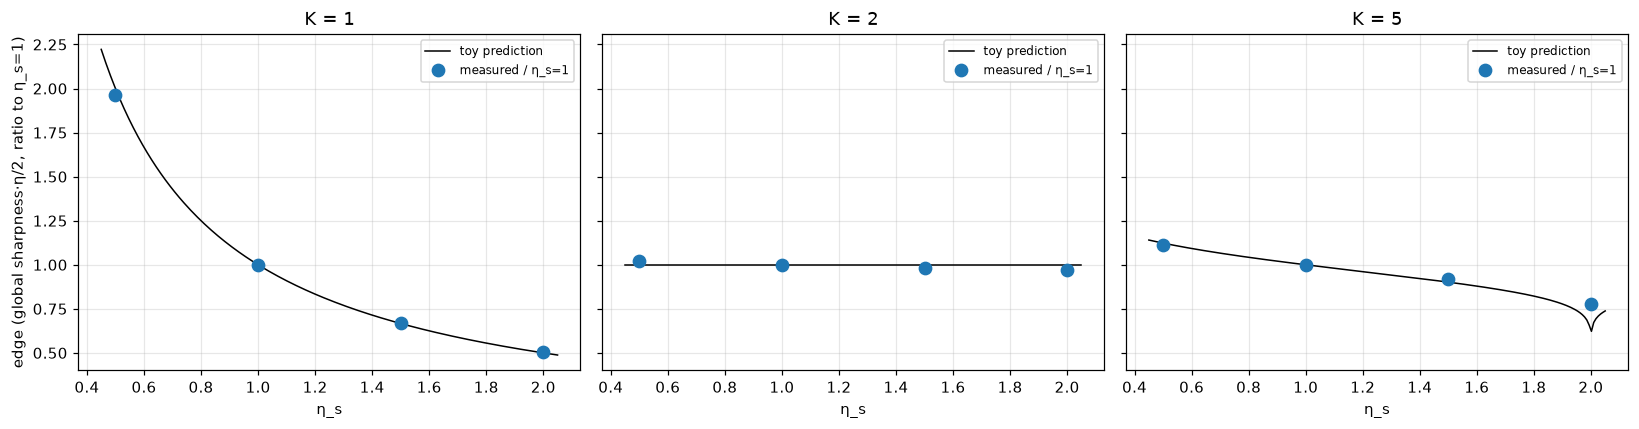

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, K in zip(axes, [1, 2, 5]):
    g = R[R.local_steps == K].sort_values("server_lr")
    s = np.linspace(0.45, 2.05, 200)
    ax.plot(s, [predicted(K, x) for x in s], "k-", lw=1, label="toy prediction")
    ax.plot(g.server_lr, g["measured / η_s=1"], "o", ms=8, label="measured / η_s=1")
    for _, r in g[g.status == "diverged"].iterrows():
        ax.annotate("diverged", (r.server_lr, 0.55), ha="center", color="r")
    ax.set_title(f"K = {K}"); ax.set_xlabel("η_s"); ax.legend(fontsize=8)
axes[0].set_ylabel("edge (global sharpness·η/2, ratio to η_s=1)"); plt.tight_layout(); plt.show()

## 2. Trajectories

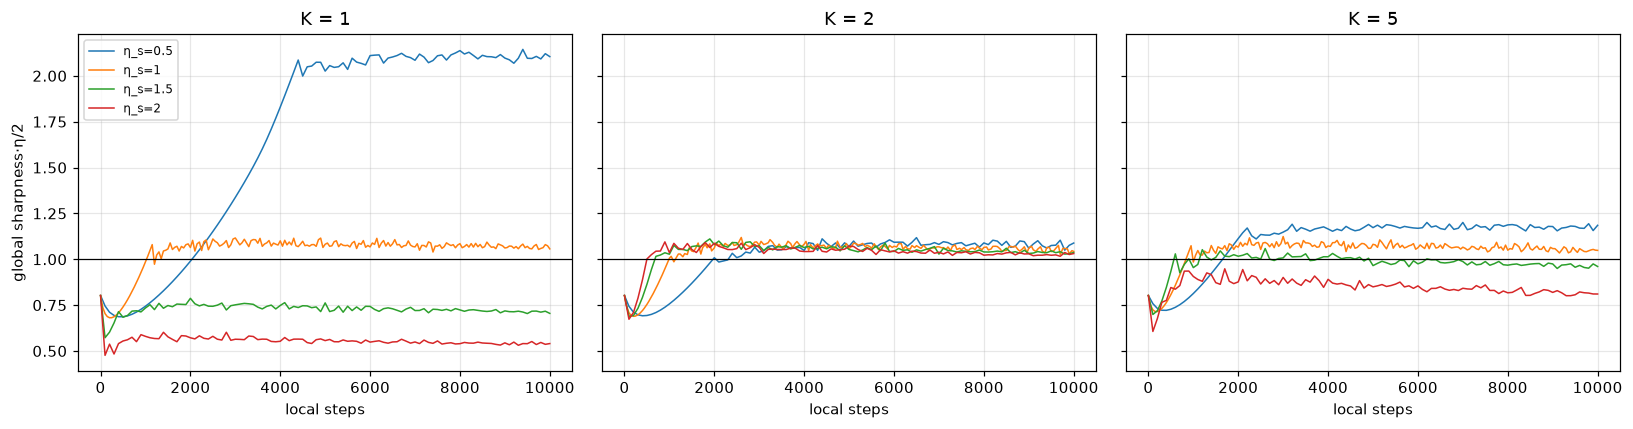

In [ ]:
T = pd.concat([obs.load_traj("fedavg_server_lr"),
               (lambda t: t[(t.alpha == np.inf) & (t.seed == 0) & np.isclose(t.lr, 0.02) & t.local_steps.isin([1, 2, 5])])(obs.load_traj("fedavg_main"))])
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, K in zip(axes, [1, 2, 5]):
    for s, g in T[T.local_steps == K].groupby("server_lr"):
        g = g.dropna(subset=["sharpness"]); ax.plot(g.steps, g.sharpness * g.lr / 2, lw=1, label=f"η_s={s:g}")
    edge_line(ax); ax.set_title(f"K = {K}"); ax.set_xlabel("local steps")
axes[0].set_ylabel("global sharpness·η/2"); axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

## 3. Same data in per-step c_eff (H1 law)

Using the toy round-map eigenvalue at the measured sharpness, `τ = η_s(1 − (1 − ηλ)ᴷ)`, growth per round `g = |1 − τ|`, per-step `c_eff = (1 + g^{1/K})/2`. If the H1 law holds under η_s, c_eff ≈ GD's overshoot (≈1.06–1.08) everywhere.

local_steps,1,2,5
server_lr,,,
0.5,1.052,1.042,1.062
1.0,1.071,1.058,1.057
1.5,1.077,1.060,1.050
2.0,1.084,1.056,1.020


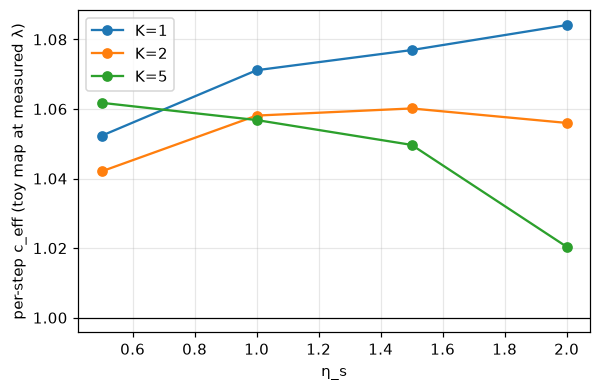

In [ ]:
x = 2 * R.eq_sharp_norm
R["tau_toy"] = R.server_lr * (1 - (1 - x) ** R.local_steps)
R["c_eff"] = (1 + (1 - R.tau_toy).abs() ** (1 / R.local_steps)) / 2
display(R.pivot(index="server_lr", columns="local_steps", values="c_eff").round(3))
fig, ax = plt.subplots(figsize=(6, 3.8))
for K, g in R.groupby("local_steps"):
    g = g.sort_values("server_lr"); ax.plot(g.server_lr, g.c_eff, "o-", label=f"K={K}")
edge_line(ax); ax.set_xlabel("η_s"); ax.set_ylabel("per-step c_eff (toy map at measured λ)"); ax.legend(); plt.show()

## Conclusions

1. **H4 holds: the server step moves the edge as the toy predicts** (ratio to η_s = 1):
   - K = 1: 1.965 / 0.670 / 0.506 vs predicted 2 / 0.667 / 0.5.
   - K = 2: 1.022 / 0.984 / 0.972 vs 1 (even K ignores η_s; small downward drift of ≤3%).
   - K = 5: 1.115 / 0.918 vs 1.123 / 0.901 at η_s = 0.5 / 1.5.
2. **One miss: K = 5, η_s = 2** measures 0.778 vs predicted 0.5. At η_s = 2 the odd-K prediction is a cusp (see the plot): past ηλ = 1 the per-round growth is only 1 + 2(ηλ − 1)ᴷ, which is ≈1.2 per round (≈1.04 per step) even at 0.82. The instability is too weak to pull sharpness down to 0.5, so it settles where the overshoot is GD-like.
3. **Self-stabilization shows up as catapults.** K = 1 at η_s = 1.5 and 2 starts above its edge (0.80 > 0.67, 0.5); sharpness drops to ≈0.57 and ≈0.48 in the first 100 steps and then stays there. No run diverged.
4. **The H1 per-step law survives η_s.** c_eff from the toy map at measured λ is 1.04–1.08 in 11 of 12 runs (K = 5, η_s = 2: 1.02). So "frozen round-map growth per local step ≈ GD's EoS overshoot" holds across server steps too.

Caveats: IID only, one seed, η = 0.02; the round map is computed from the toy formula at measured λ, not measured on the network.